### Checking Dataset

In [1]:
from pathlib import Path

# Location of your existing dataset
DATASET_PATH = Path(
    r"F:\Code\Deep_Learning\Project_Car_Damage_Prediction\Dataset"
)

# Check whether the dataset exists
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

print("Dataset found successfully!")
print(f"Dataset location: {DATASET_PATH}")

# Count images in each class folder
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

for folder in sorted(DATASET_PATH.iterdir()):
    if folder.is_dir():
        image_count = sum(
            1
            for file in folder.rglob("*")
            if file.is_file()
            and file.suffix.lower() in image_extensions
        )

        print(f"{folder.name}: {image_count} images")

Dataset found successfully!
Dataset location: F:\Code\Deep_Learning\Project_Car_Damage_Prediction\Dataset
F_Breakage: 500 images
F_Crushed: 400 images
F_Normal: 500 images
R_Breakage: 300 images
R_Crushed: 300 images
R_Normal: 300 images


### Data Visualization

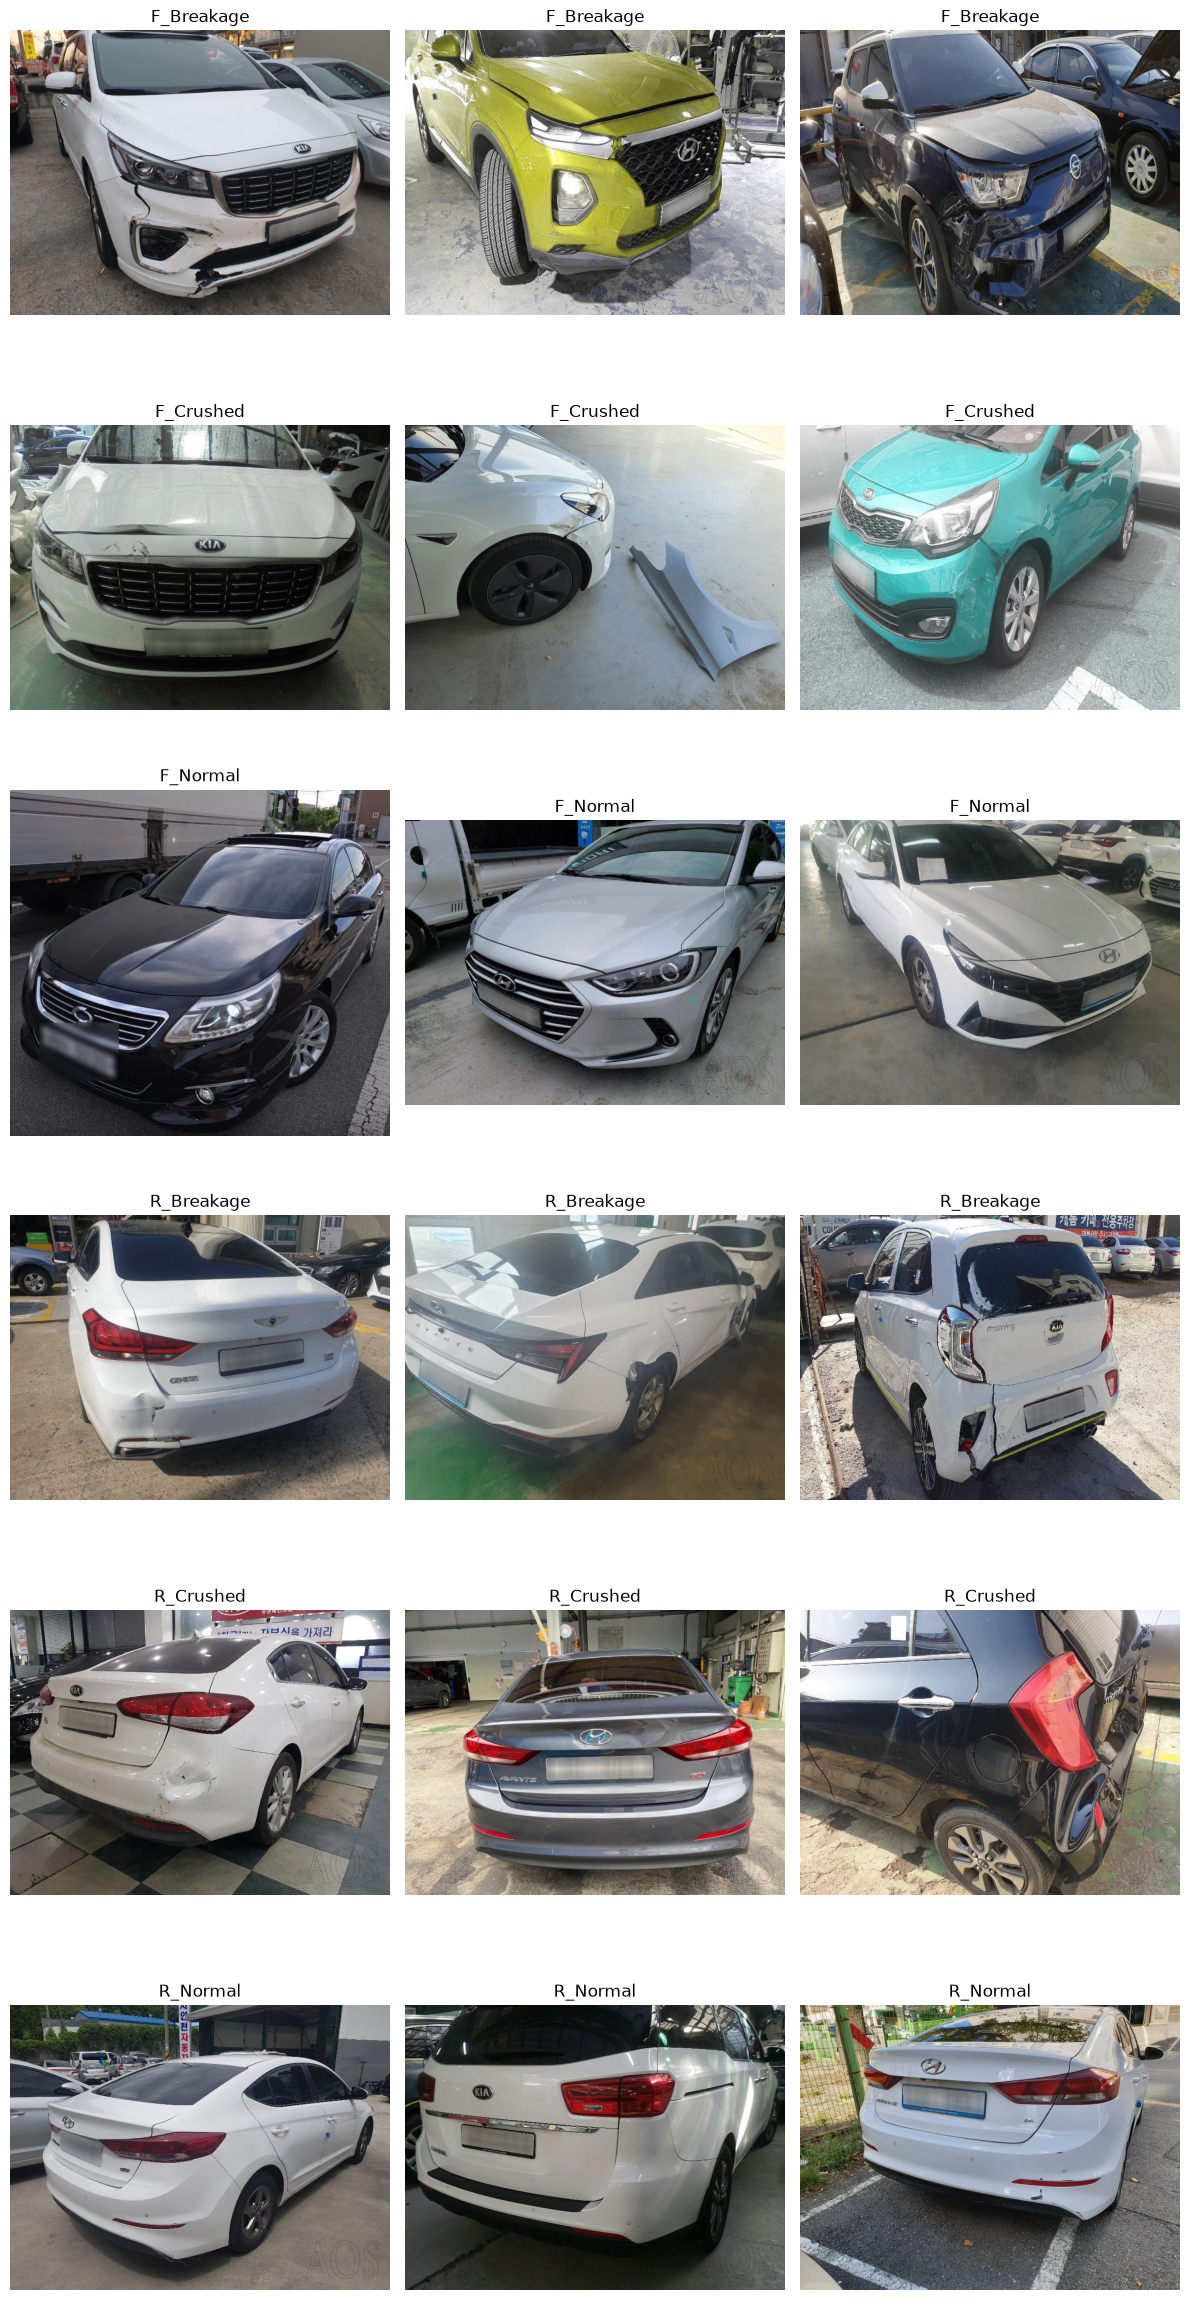

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

class_folders = sorted(
    folder
    for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
)

number_of_classes = len(class_folders)

fig, axes = plt.subplots(
    number_of_classes,
    3,
    figsize=(12, 4 * number_of_classes)
)

if number_of_classes == 1:
    axes = axes.reshape(1, -1)

for row, folder in enumerate(class_folders):
    images = [
        file
        for file in folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ][:3]

    for col in range(3):
        ax = axes[row, col]

        if col < len(images):
            with Image.open(images[col]) as image:
                ax.imshow(image.convert("RGB"))

            ax.set_title(folder.name)
        else:
            ax.set_visible(False)

        ax.axis("off")

plt.tight_layout()
plt.show()

### Build DataLoaders

In [3]:
import sys
from pathlib import Path

# Project root directory
PROJECT_ROOT = Path(
    r"F:\Code\Deep_Learning\Project_Car_Damage_Prediction"
)

# Add project root to Python import path
sys.path.insert(0, str(PROJECT_ROOT))

from src.car_damage.data import build_dataloaders

print("Data module imported successfully!")

Data module imported successfully!


In [4]:
import importlib
import sys

module_name = "src.car_damage.data"

if module_name in sys.modules:
    del sys.modules[module_name]

import src.car_damage.data as data_module

data_module = importlib.reload(data_module)

print("Loaded from:", data_module.__file__)
print("Function available:", hasattr(data_module, "build_dataloaders"))

Loaded from: F:\Code\Deep_Learning\Project_Car_Damage_Prediction\src\car_damage\data.py
Function available: True


In [5]:
import importlib
import src.car_damage.data as data_module

importlib.reload(data_module)

build_dataloaders = data_module.build_dataloaders

print("Updated data module loaded successfully!")

Updated data module loaded successfully!


### Split the Dataset into Training, Validation and Test

In [6]:
DATASET_PATH = PROJECT_ROOT / "Dataset"

data = build_dataloaders(
    dataset_dir=DATASET_PATH,
    image_size=224,
    batch_size=8,
    num_workers=0,
    random_state=42
)

train_loader = data["train_loader"]
val_loader = data["val_loader"]
test_loader = data["test_loader"]

class_names = data["class_names"]

print("Classes:", class_names)

print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Testing images:", len(test_loader.dataset))

print("Corrupt images:", len(data["corrupt_images"]))

Classes: ['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']
Training images: 1610
Validation images: 345
Testing images: 345
Corrupt images: 0


In [7]:
print("Original class distribution:")

for class_name, count in data["class_counts"].items():
    print(f"{class_name}: {count}")

Original class distribution:
F_Breakage: 500
F_Crushed: 400
F_Normal: 500
R_Breakage: 300
R_Crushed: 300
R_Normal: 300


In [8]:
from collections import Counter

for split_name, loader in [
    ("Training", train_loader),
    ("Validation", val_loader),
    ("Testing", test_loader)
]:
    labels = [label for _, label in loader.dataset.records]
    counts = Counter(labels)

    print(f"\n{split_name} distribution:")
    for class_idx, class_name in enumerate(class_names):
        print(f"{class_name}: {counts[class_idx]}")


Training distribution:
F_Breakage: 350
F_Crushed: 280
F_Normal: 350
R_Breakage: 210
R_Crushed: 210
R_Normal: 210

Validation distribution:
F_Breakage: 75
F_Crushed: 60
F_Normal: 75
R_Breakage: 45
R_Crushed: 45
R_Normal: 45

Testing distribution:
F_Breakage: 75
F_Crushed: 60
F_Normal: 75
R_Breakage: 45
R_Crushed: 45
R_Normal: 45


### Model Training

In [8]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    r"F:\Code\Deep_Learning\Project_Car_Damage_Prediction"
)

sys.path.insert(0, str(PROJECT_ROOT))

from src.car_damage.model import build_model

print("Model module imported successfully!")

Model module imported successfully!


In [9]:
model = build_model(
    num_classes=len(class_names),
    pretrained=True,
    dropout=0.3,
    fine_tune_layer4=True
)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [10]:
total_params = sum(
    param.numel()
    for param in model.parameters()
)

trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

Total parameters: 23,520,326
Trainable parameters: 14,977,030
Frozen parameters: 8,543,296
Trainable percentage: 63.68%


In [11]:
import torch

device = torch.device("cpu")
model = model.to(device)

images, labels = next(iter(train_loader))

model.eval()

with torch.no_grad():
    outputs = model(images.to(device))

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Actual labels:", labels)

Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 6])
Actual labels: tensor([0, 2, 3, 5, 2, 2, 5, 0])


In [12]:
import torch
import torch.nn as nn
from src.car_damage.model import build_model
from src.car_damage.train import set_batchnorm_eval

model = build_model(
    num_classes=6,
    pretrained=True,
    dropout=0.3,
    fine_tune_layer4=True
)

model.train()
set_batchnorm_eval(model)

bn_layers = [
    module for module in model.modules()
    if isinstance(module, nn.modules.batchnorm._BatchNorm)
]

print("Total BatchNorm layers:", len(bn_layers))
print("BatchNorm layers in training mode:",
      sum(layer.training for layer in bn_layers))
print("BatchNorm layers in evaluation mode:",
      sum(not layer.training for layer in bn_layers))

Total BatchNorm layers: 53
BatchNorm layers in training mode: 0
BatchNorm layers in evaluation mode: 53


In [13]:
import importlib
import src.car_damage.train as train_module

importlib.reload(train_module)

from src.car_damage.train import train_model

print("Training module imported successfully!")

Training module imported successfully!


### Train the Model

In [32]:
from src.car_damage.train import train_model

model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=3,
    learning_rate=0.0001,
    patience=2,
    save_path="artifacts/best_model.pth"
)


Epoch 1/3


Training:   0%|          | 0/202 [00:00<?, ?it/s]

F:\Code\Deep_Learning\Project_Car_Damage_Prediction\.venv\Lib\site-packages\torch\cuda\__init__.py:497: UserWarning: Found GPU0 NVIDIA GeForce 940MX which is of compute capability (CC) 5.0.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0
- 8.6 which supports hardware CC >=8.6,<9.0
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.15.0+cu132 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.15.0 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
F:\Code\Deep_Learning\Project_Car_Damage_Prediction\.venv\Lib\site-packages\torch\cuda\__init__.py:627: UserWarning: 
NVIDIA GeForce 94

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 1.0225
Training Accuracy: 0.5484
Validation Loss: 0.8562
Validation Accuracy: 0.6000
Validation Macro F1: 0.5337
Epoch Time: 6.25 minutes
Best macro F1 checkpoint saved!

Epoch 2/3


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 0.7203
Training Accuracy: 0.6783
Validation Loss: 0.7810
Validation Accuracy: 0.6232
Validation Macro F1: 0.5494
Epoch Time: 5.60 minutes
Best macro F1 checkpoint saved!

Epoch 3/3


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 0.5631
Training Accuracy: 0.7516
Validation Loss: 0.6280
Validation Accuracy: 0.7333
Validation Macro F1: 0.6735
Epoch Time: 5.53 minutes
Best macro F1 checkpoint saved!

Training completed!
Best validation macro F1: 0.6735
Best model saved at: artifacts\best_model.pth


In [33]:
import torch
import numpy as np

model.eval()

device = torch.device("cpu")
model = model.to(device)

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total validation samples:", len(y_true))
print("Predictions generated successfully!")

Total validation samples: 345
Predictions generated successfully!


### Classification Report

In [34]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

  F_Breakage     0.9306    0.8933    0.9116        75
   F_Crushed     0.6742    1.0000    0.8054        60
    F_Normal     1.0000    0.7333    0.8462        75
  R_Breakage     0.7143    0.1111    0.1923        45
   R_Crushed     0.4271    0.9111    0.5816        45
    R_Normal     0.9615    0.5556    0.7042        45

    accuracy                         0.7333       345
   macro avg     0.7846    0.7007    0.6735       345
weighted avg     0.8112    0.7333    0.7150       345



### Confusion Matrix

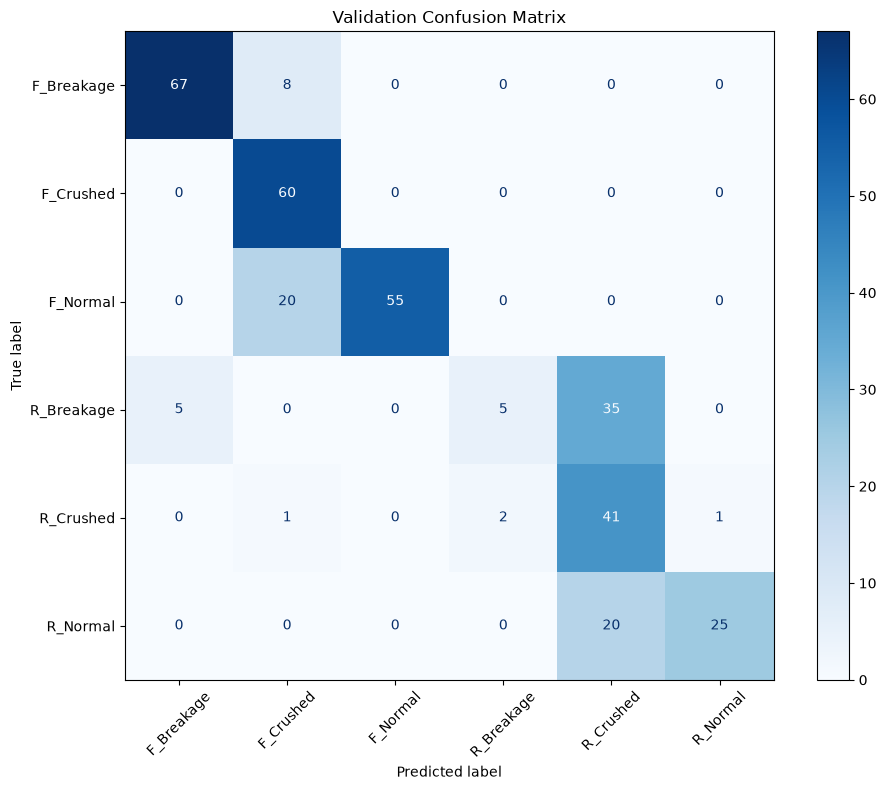

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=45
)

plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


Actual: F_Breakage | Predicted: F_Crushed
Examples found: 3


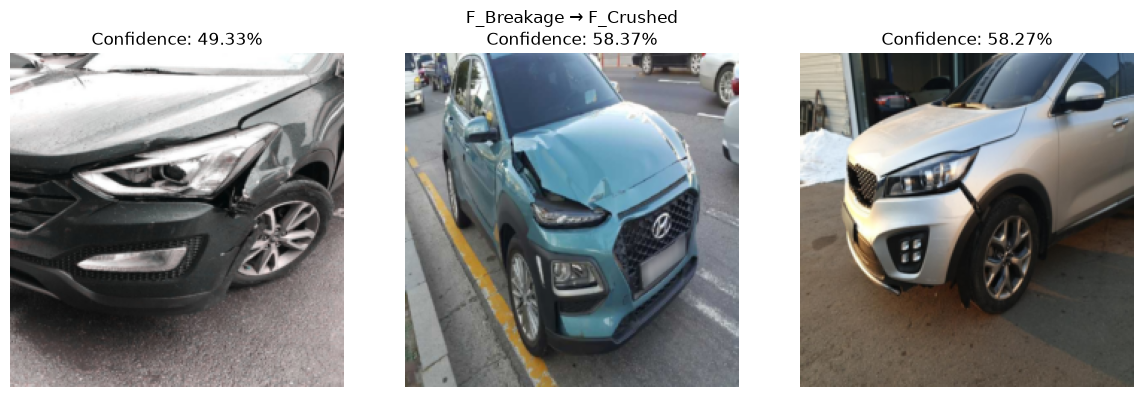


Actual: R_Breakage | Predicted: R_Crushed
Examples found: 3


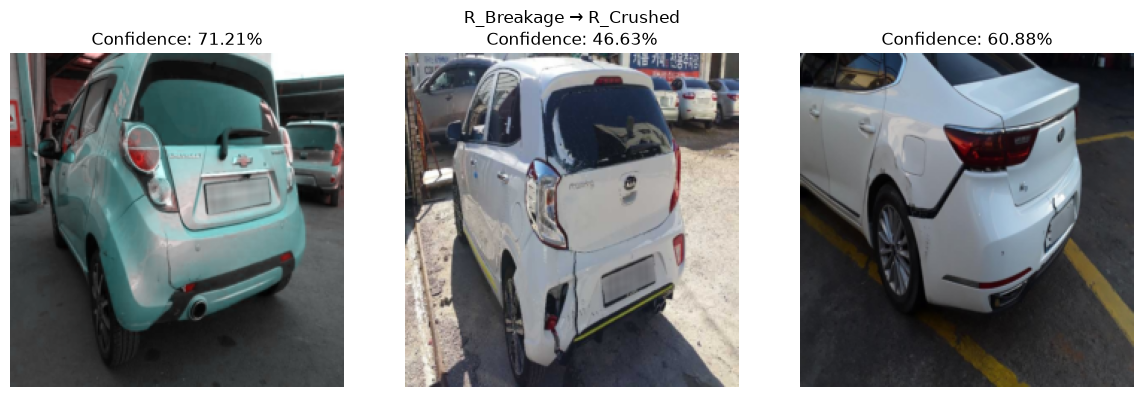


Actual: R_Normal | Predicted: R_Crushed
Examples found: 3


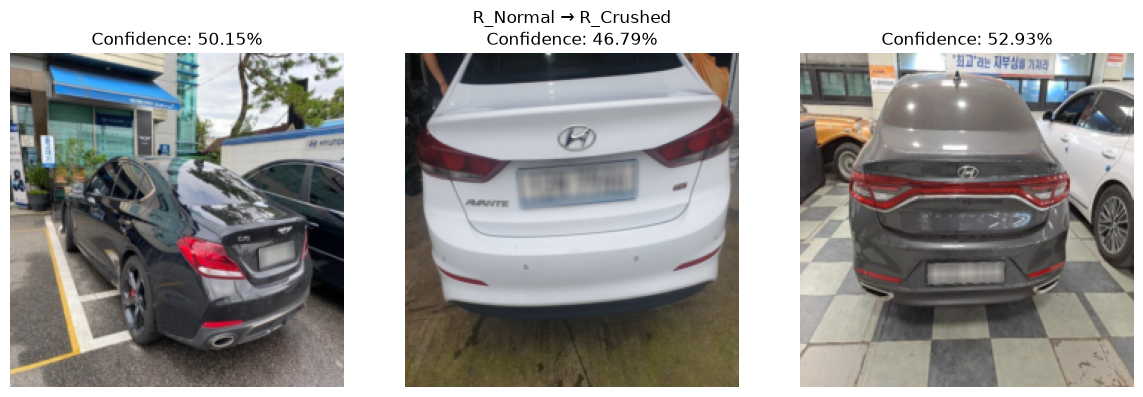

In [36]:
import torch
import matplotlib.pyplot as plt
import numpy as np

model.eval()

# ImageNet normalization parameters
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Misclassification pairs to investigate
target_pairs = [
    ("F_Breakage", "F_Crushed"),
    ("R_Breakage", "R_Crushed"),
    ("R_Normal", "R_Crushed")
]

examples = {pair: [] for pair in target_pairs}

with torch.no_grad():

    for images, labels in val_loader:

        outputs = model(images.to(device))
        probabilities = torch.softmax(outputs, dim=1)

        predictions = torch.argmax(probabilities, dim=1)

        for i in range(len(labels)):

            actual = class_names[labels[i].item()]
            predicted = class_names[predictions[i].item()]

            pair = (actual, predicted)

            if pair in examples and len(examples[pair]) < 3:

                confidence = probabilities[i, predictions[i]].item()

                # Reverse ImageNet normalization
                image = images[i].cpu() * std + mean
                image = torch.clamp(image, 0, 1)

                examples[pair].append(
                    (image.permute(1, 2, 0).numpy(), confidence)
                )

# Display examples
for pair, samples in examples.items():

    print(f"\nActual: {pair[0]} | Predicted: {pair[1]}")
    print("Examples found:", len(samples))

    if not samples:
        continue

    fig, axes = plt.subplots(1, len(samples), figsize=(12, 4))

    if len(samples) == 1:
        axes = [axes]

    for ax, (image, confidence) in zip(axes, samples):

        ax.imshow(image)
        ax.set_title(f"Confidence: {confidence:.2%}")
        ax.axis("off")

    plt.suptitle(f"{pair[0]} → {pair[1]}")
    plt.tight_layout()
    plt.show()

## Exp1: ResNet50 with Learning Rate = 0.0001

### Load the Model

In [32]:
from src.car_damage.model import build_model

model_exp1 = build_model(
    num_classes=6,
    pretrained=True,
    dropout=0.3,
    fine_tune_layer4=True
)

print("Fresh ResNet50 model created!")

Fresh ResNet50 model created!


### Train the Model

In [33]:
model_exp1, history_exp1 = train_model(
    model=model_exp1,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=3,
    backbone_lr=0.00001,
    classifier_lr=0.0001,
    patience=2,
    save_path="artifacts/best_model_exp1.pth"
)


Epoch 1/3


Validation: 100%|██████████| 44/44 [00:44<00:00,  1.01s/it]


Training Loss: 1.4489
Training Accuracy: 0.4112
Validation Loss: 0.9676
Validation Accuracy: 0.5971
Epoch Time: 5.58 minutes
Best model checkpoint saved!

Epoch 2/3


Validation: 100%|██████████| 44/44 [00:43<00:00,  1.01it/s]


Training Loss: 0.8138
Training Accuracy: 0.6255
Validation Loss: 0.8069
Validation Accuracy: 0.6116
Epoch Time: 5.35 minutes
Best model checkpoint saved!

Epoch 3/3


Validation: 100%|██████████| 44/44 [00:46<00:00,  1.06s/it]


Training Loss: 0.6514
Training Accuracy: 0.7261
Validation Loss: 0.6551
Validation Accuracy: 0.6899
Epoch Time: 16.77 minutes
Best model checkpoint saved!

Training completed!
Best validation loss: 0.6551
Best model saved at: artifacts\best_model_exp1.pth


### Classification Report

In [34]:
import torch
import numpy as np
from sklearn.metrics import classification_report

model_exp1.eval()

device = torch.device("cpu")

y_true_exp1 = []
y_pred_exp1 = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model_exp1(images)

        predictions = torch.argmax(outputs, dim=1)

        y_true_exp1.extend(labels.numpy())
        y_pred_exp1.extend(predictions.cpu().numpy())

print(
    classification_report(
        y_true_exp1,
        y_pred_exp1,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

  F_Breakage     0.7340    0.9200    0.8166        75
   F_Crushed     0.8235    0.4667    0.5957        60
    F_Normal     0.7816    0.9067    0.8395        75
  R_Breakage     0.6875    0.4889    0.5714        45
   R_Crushed     0.4815    0.2889    0.3611        45
    R_Normal     0.5352    0.8444    0.6552        45

    accuracy                         0.6899       345
   macro avg     0.6739    0.6526    0.6399       345
weighted avg     0.6950    0.6899    0.6707       345



### Confusion Matrix

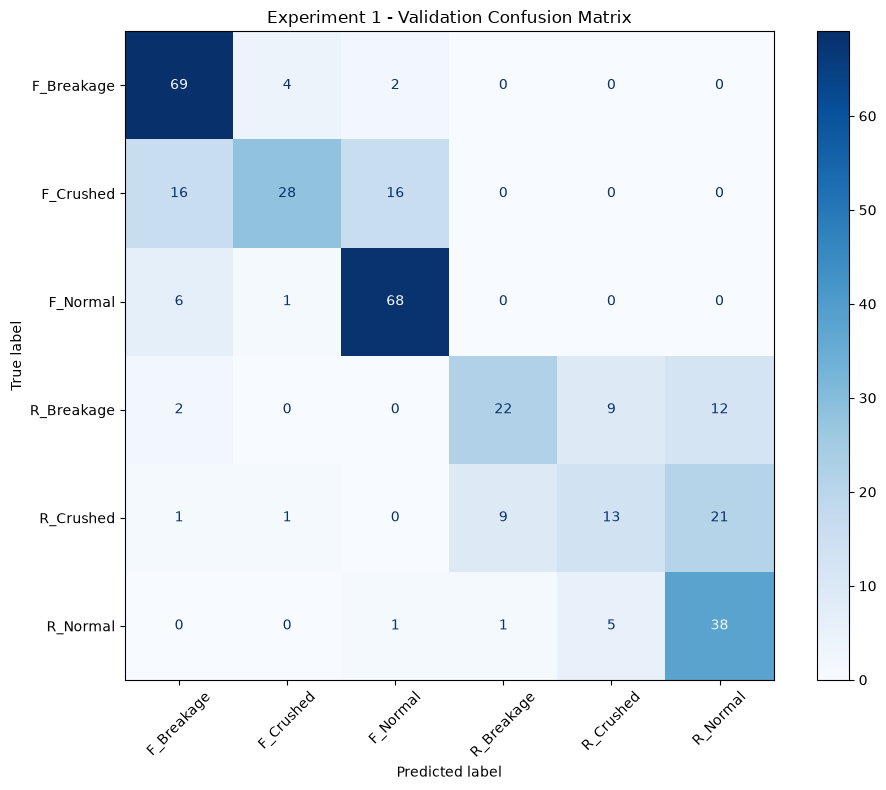

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_exp1 = confusion_matrix(
    y_true_exp1,
    y_pred_exp1,
    labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_exp1,
    display_labels=class_names
)

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=45
)

plt.title("Experiment 1 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Exp2: Macro F1-based checkpoint selection

### Reload the module

In [37]:
import importlib
import src.car_damage.train as train_module

importlib.reload(train_module)

from src.car_damage.train import train_model

print("Experiment 2 training module loaded successfully!")

Experiment 2 training module loaded successfully!


### Create RestNet50 Model

In [38]:
from src.car_damage.model import build_model

model_exp2 = build_model(
    num_classes=6,
    pretrained=True,
    dropout=0.3,
    fine_tune_layer4=True
)

print("Fresh ResNet50 created for Experiment 2!")

Fresh ResNet50 created for Experiment 2!


### Train the Model

In [39]:
model_exp2, history_exp2 = train_model(
    model=model_exp2,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    learning_rate=0.0001,
    patience=2,
    save_path="artifacts/best_model_exp2.pth"
)


Epoch 1/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 1.0049
Training Accuracy: 0.5509
Validation Loss: 0.8996
Validation Accuracy: 0.6522
Validation Macro F1: 0.5782
Epoch Time: 5.62 minutes
Best macro F1 checkpoint saved!

Epoch 2/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

... (6 outputs left out)

Training Loss: 0.4434
Training Accuracy: 0.8081
Validation Loss: 0.4841
Validation Accuracy: 0.8203
Validation Macro F1: 0.7962
Epoch Time: 8.36 minutes
Best macro F1 checkpoint saved!

Epoch 5/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 0.4059
Training Accuracy: 0.8298
Validation Loss: 0.5546
Validation Accuracy: 0.7884
Validation Macro F1: 0.7593
Epoch Time: 5.48 minutes
No macro F1 improvement: 1/2

Training completed!
Best validation macro F1: 0.7962
Best model saved at: artifacts\best_model_exp2.pth


### Model Evaluation

In [42]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

device = torch.device("cpu")

model_exp2.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model_exp2(images)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Classification report
report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# display(report_df.round(4))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [41]:
from IPython.display import display as show_table

show_table(report_df.round(4))

,precision,recall,f1-score,support
F_Breakage,0.8987,0.9467,0.9221,75.0000
F_Crushed,0.8421,0.8000,0.8205,60.0000
F_Normal,0.8933,0.8933,0.8933,75.0000
R_Breakage,0.7091,0.8667,0.7800,45.0000
R_Crushed,0.6571,0.5111,0.5750,45.0000
R_Normal,0.7955,0.7778,0.7865,45.0000
accuracy,0.8203,0.8203,0.8203,0.8203
macro avg,0.7993,0.7993,0.7962,345.0000
weighted avg,0.8180,0.8203,0.8167,345.0000


### Confusion Matrix

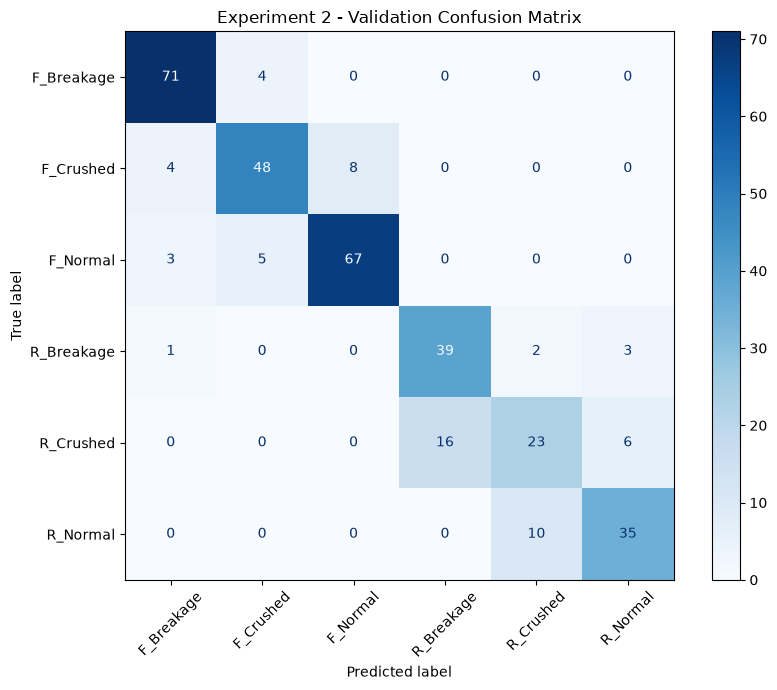

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("Experiment 2 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Exp3: class-weighted CrossEntropyLoss

In [14]:
from collections import Counter
import torch

# Count labels in the training dataset only
train_labels = [
    label for _, label in train_loader.dataset.records
]

class_counts = Counter(train_labels)

print("Training class distribution:")

for class_idx, class_name in enumerate(class_names):
    print(f"{class_name}: {class_counts[class_idx]}")

# Calculate balanced class weights
num_classes = len(class_names)
total_samples = len(train_labels)

class_weights = torch.tensor(
    [
        total_samples / (num_classes * class_counts[i])
        for i in range(num_classes)
    ],
    dtype=torch.float32
)

print("\nCalculated class weights:")

for class_name, weight in zip(class_names, class_weights):
    print(f"{class_name}: {weight.item():.4f}")

Training class distribution:
F_Breakage: 350
F_Crushed: 280
F_Normal: 350
R_Breakage: 210
R_Crushed: 210
R_Normal: 210

Calculated class weights:
F_Breakage: 0.7667
F_Crushed: 0.9583
F_Normal: 0.7667
R_Breakage: 1.2778
R_Crushed: 1.2778
R_Normal: 1.2778


### Reload the model

In [15]:
import importlib
import src.car_damage.train as train_module

importlib.reload(train_module)

train_model = train_module.train_model

import inspect
print(inspect.signature(train_model))

(model, train_loader, val_loader, epochs=5, learning_rate=0.0001, patience=2, save_path='artifacts/best_model_exp3.pth', class_weights=None)


### Create Fresh model

In [16]:
from src.car_damage.model import build_model

model_exp3 = build_model(
    num_classes=6,
    pretrained=True,
    dropout=0.3,
    fine_tune_layer4=True
)

print("Fresh Experiment 3 model created!")

Fresh Experiment 3 model created!


### Model Training

In [17]:
model_exp3, history_exp3 = train_model(
    model=model_exp3,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    learning_rate=0.0001,
    patience=2,
    save_path="artifacts/best_model_exp3.pth",
    class_weights=class_weights
)


Epoch 1/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

F:\Code\Deep_Learning\Project_Car_Damage_Prediction\.venv\Lib\site-packages\torch\cuda\__init__.py:497: UserWarning: Found GPU0 NVIDIA GeForce 940MX which is of compute capability (CC) 5.0.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0
- 8.6 which supports hardware CC >=8.6,<9.0
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.15.0+cu132 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.15.0 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
F:\Code\Deep_Learning\Project_Car_Damage_Prediction\.venv\Lib\site-packages\torch\cuda\__init__.py:627: UserWarning: 
NVIDIA GeForce 94

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 1.0211
Training Accuracy: 0.5758
Validation Loss: 0.7803
Validation Accuracy: 0.6406
Validation Macro F1: 0.5557
Epoch Time: 5.74 minutes
Best macro F1 checkpoint saved!

Epoch 2/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

... (4 outputs left out)

Training Loss: 0.5773
Training Accuracy: 0.7522
Validation Loss: 0.6915
Validation Accuracy: 0.7159
Validation Macro F1: 0.6780
Epoch Time: 5.52 minutes
No macro F1 improvement: 1/2

Epoch 4/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 0.5142
Training Accuracy: 0.7888
Validation Loss: 0.5426
Validation Accuracy: 0.7565
Validation Macro F1: 0.7251
Epoch Time: 5.54 minutes
No macro F1 improvement: 2/2
Early stopping triggered!

Training completed!
Best validation macro F1: 0.7397
Best model saved at: artifacts\best_model_exp3.pth


### Model Evaluation

In [19]:
import torch
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

model_exp3.eval()

all_labels_exp3 = []
all_predictions_exp3 = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model_exp3(images)
        predictions = torch.argmax(outputs, dim=1)

        all_labels_exp3.extend(labels.cpu().numpy())
        all_predictions_exp3.extend(predictions.cpu().numpy())

report_exp3 = classification_report(
    all_labels_exp3,
    all_predictions_exp3,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_exp3_df = pd.DataFrame(report_exp3).transpose()

# from IPython.display import display as show_table

# show_table(report_df.round(4))

### Confusion Matrix

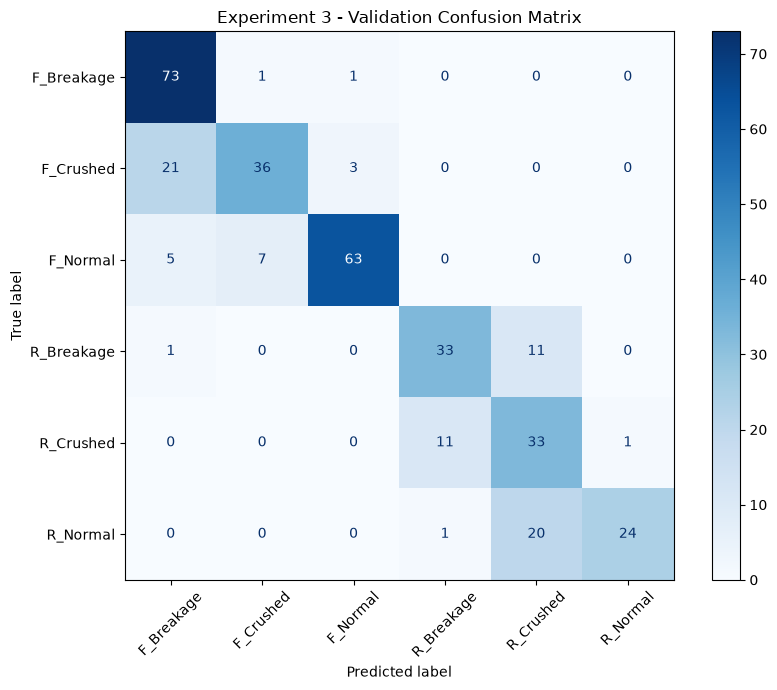

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_exp3 = confusion_matrix(
    all_labels_exp3,
    all_predictions_exp3
)

fig, ax = plt.subplots(figsize=(9, 7))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_exp3,
    display_labels=class_names
)

cm_display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("Experiment 3 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Experiment 4: Fine-tuning a deeper part of ResNet50.

### Create Fresh model

In [22]:
import importlib
import src.car_damage.model as model_module

importlib.reload(model_module)

from src.car_damage.model import build_model

model_exp4 = build_model(
    num_classes=6,
    pretrained=True,
    dropout=0.3,
    fine_tune_layer3=True,
    fine_tune_layer4=True
)

print("Fresh Experiment 4 model created!")

Fresh Experiment 4 model created!


### Verify Trainable Parameters

In [23]:
total_params = sum(
    p.numel() for p in model_exp4.parameters()
)

trainable_params = sum(
    p.numel() for p in model_exp4.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {frozen_params:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

print("\nLayer trainability:")

for layer_name in ["layer1", "layer2", "layer3", "layer4", "fc"]:
    layer = getattr(model_exp4, layer_name)

    trainable = any(
        p.requires_grad for p in layer.parameters()
    )

    print(f"{layer_name}: {'Trainable' if trainable else 'Frozen'}")

Total parameters: 23,520,326
Trainable parameters: 22,075,398
Frozen parameters: 1,444,928
Trainable percentage: 93.86%

Layer trainability:
layer1: Frozen
layer2: Frozen
layer3: Trainable
layer4: Trainable
fc: Trainable


In [24]:
import importlib
import inspect

import src.car_damage.train as train_module

importlib.reload(train_module)

train_model = train_module.train_model

print(inspect.signature(train_model))

(model, train_loader, val_loader, epochs=5, patience=2, save_path='artifacts/best_model_exp4.pth', class_weights=None, layer3_lr=1e-05, layer4_lr=1e-05, classifier_lr=0.0001, weight_decay=0.0001)


In [25]:
optimizer_check = torch.optim.Adam(
    [
        {"params": model_exp4.layer3.parameters(), "lr": 1e-5},
        {"params": model_exp4.layer4.parameters(), "lr": 1e-5},
        {"params": model_exp4.fc.parameters(), "lr": 1e-4}
    ],
    weight_decay=1e-4
)

for i, group in enumerate(optimizer_check.param_groups):
    print(
        f"Parameter group {i + 1}: "
        f"Learning rate = {group['lr']}"
    )

Parameter group 1: Learning rate = 1e-05
Parameter group 2: Learning rate = 1e-05
Parameter group 3: Learning rate = 0.0001


### Train the Model

In [26]:
model_exp4, history_exp4 = train_model(
    model=model_exp4,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    patience=2,
    save_path="artifacts/best_model_exp4.pth",
    class_weights=class_weights,
    layer3_lr=1e-5,
    layer4_lr=1e-5,
    classifier_lr=1e-4,
    weight_decay=1e-4
)


Epoch 1/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 1.4027
Training Accuracy: 0.4373
Validation Loss: 0.9001
Validation Accuracy: 0.5826
Validation Macro F1: 0.5624
Epoch Time: 7.45 minutes
Best macro F1 checkpoint saved!

Epoch 2/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

... (6 outputs left out)

Training Loss: 0.5434
Training Accuracy: 0.7758
Validation Loss: 0.8404
Validation Accuracy: 0.6464
Validation Macro F1: 0.5985
Epoch Time: 7.62 minutes
No macro F1 improvement: 1/2

Epoch 5/5


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

Training Loss: 0.4396
Training Accuracy: 0.8193
Validation Loss: 0.8160
Validation Accuracy: 0.6957
Validation Macro F1: 0.6623
Epoch Time: 7.33 minutes
No macro F1 improvement: 2/2
Early stopping triggered!

Training completed!
Best validation macro F1: 0.7066
Best model saved at: artifacts\best_model_exp4.pth


In [27]:
checkpoint_exp4 = torch.load(
    "artifacts/best_model_exp4.pth",
    map_location=device,
    weights_only=False
)

print("Best epoch:", checkpoint_exp4["epoch"])
print("Best macro F1:", checkpoint_exp4["best_val_macro_f1"])
print("Validation accuracy:", checkpoint_exp4["val_accuracy"])

model_exp4.load_state_dict(
    checkpoint_exp4["model_state_dict"]
)

model_exp4.eval()

Best epoch: 3
Best macro F1: 0.7065983130866808
Validation accuracy: 0.7217391304347827


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

### Classification Report

In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

all_labels_exp4 = []
all_predictions_exp4 = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model_exp4(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels_exp4.extend(labels.cpu().numpy())
        all_predictions_exp4.extend(predictions.cpu().numpy())

report_exp4 = classification_report(
    all_labels_exp4,
    all_predictions_exp4,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_exp4_df = pd.DataFrame(report_exp4).transpose()

display(report_exp4_df.round(4))

,precision,recall,f1-score,support
F_Breakage,0.9216,0.6267,0.7460,75.0000
F_Crushed,0.5408,0.8833,0.6709,60.0000
F_Normal,0.9206,0.7733,0.8406,75.0000
R_Breakage,0.7556,0.7556,0.7556,45.0000
R_Crushed,0.6538,0.3778,0.4789,45.0000
R_Normal,0.6452,0.8889,0.7477,45.0000
accuracy,0.7217,0.7217,0.7217,0.7217
macro avg,0.7396,0.7176,0.7066,345.0000
weighted avg,0.7625,0.7217,0.7201,345.0000


### Confusion Matrix

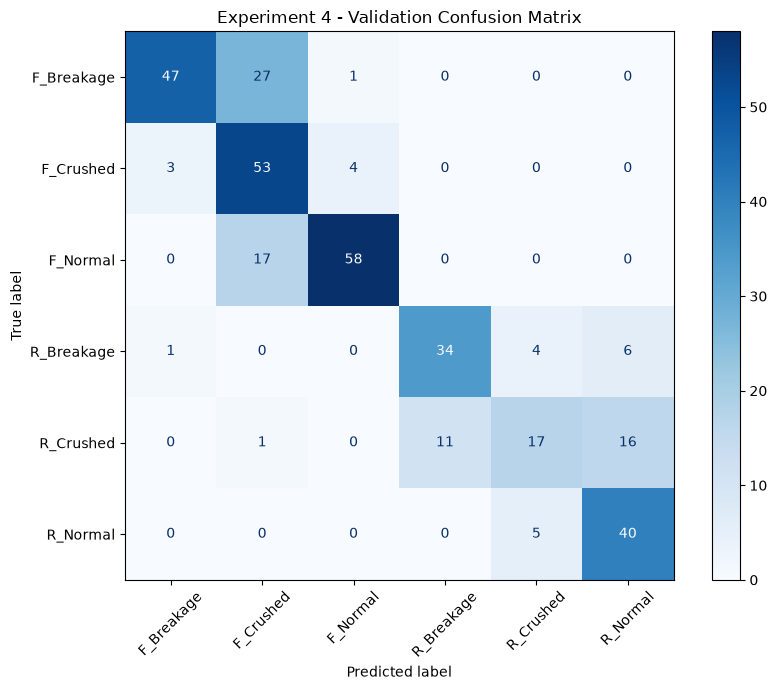

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_exp4 = confusion_matrix(
    all_labels_exp4,
    all_predictions_exp4
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm_exp4,
    display_labels=class_names
).plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("Experiment 4 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

### Load the selected Experiment 2 checkpoint

In [34]:
from pathlib import Path
import torch

from src.car_damage.model import build_model

# Project paths
PROJECT_ROOT = Path(
    r"F:\Code\Deep_Learning\Project_Car_Damage_Prediction"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT / "notebooks" / "artifacts" / "best_model_exp2.pth"
)

# Use CPU for inference
device = torch.device("cpu")

# Load checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

# Recreate the Experiment 2 architecture
final_model = build_model(
    num_classes=6,
    pretrained=True,
    dropout=0.3,
    fine_tune_layer3=False,
    fine_tune_layer4=True
)

# Load trained weights
final_model.load_state_dict(checkpoint["model_state_dict"])

# Set model to evaluation mode
final_model.to(device)
final_model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Selected Epoch:", checkpoint["epoch"])
print("Validation Accuracy:", round(checkpoint["val_accuracy"] * 100, 2), "%")
print("Validation Macro F1:", round(checkpoint["best_val_macro_f1"] * 100, 2), "%")

Model loaded successfully!
Device: cpu
Selected Epoch: 4
Validation Accuracy: 82.03 %
Validation Macro F1: 79.62 %


### Evaluating Model Performance on the Test Dataset

In [35]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Store actual and predicted labels
all_labels = []
all_predictions = []

final_model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = final_model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Convert lists to NumPy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_true, y_pred)

test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("FINAL TEST SET PERFORMANCE")
print("-" * 40)
print(f"Test Accuracy       : {test_accuracy:.4f}")
print(f"Test Precision     : {test_precision:.4f}")
print(f"Test Recall        : {test_recall:.4f}")
print(f"Test Macro F1      : {test_macro_f1:.4f}")
print(f"Test Weighted F1   : {test_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

FINAL TEST SET PERFORMANCE
----------------------------------------
Test Accuracy       : 0.8116
Test Precision     : 0.8057
Test Recall        : 0.7972
Test Macro F1      : 0.7952
Test Weighted F1   : 0.8054

Classification Report:
              precision    recall  f1-score   support

  F_Breakage       0.88      0.93      0.90        75
   F_Crushed       0.83      0.58      0.69        60
    F_Normal       0.80      0.93      0.86        75
  R_Breakage       0.73      0.84      0.78        45
   R_Crushed       0.71      0.60      0.65        45
    R_Normal       0.89      0.89      0.89        45

    accuracy                           0.81       345
   macro avg       0.81      0.80      0.80       345
weighted avg       0.81      0.81      0.81       345



### Confusion Matrix

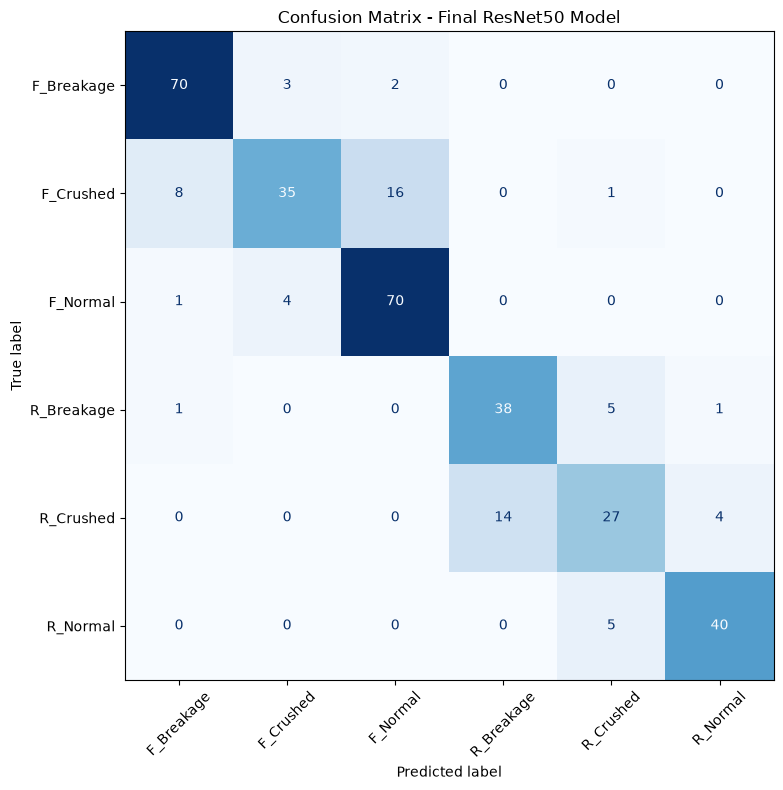

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

# Visualize confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

cm_display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)

plt.title("Confusion Matrix - Final ResNet50 Model")
plt.tight_layout()
plt.show()

### Loading the Trained Model for Inference

In [9]:
from src.car_damage.predict import load_trained_model

# Define checkpoint path
CHECKPOINT_PATH = (
    PROJECT_ROOT / "notebooks" / "artifacts" / "best_model_exp2.pth"
)

# Load trained model
inference_model, inference_device = load_trained_model(
    checkpoint_path=CHECKPOINT_PATH
)

print("Inference model loaded successfully!")
print("Device:", inference_device)
print("Architecture: ResNet50")
print("Number of classes:", len(class_names))

Inference model loaded successfully!
Device: cpu
Architecture: ResNet50
Number of classes: 6


### Single Image Prediction

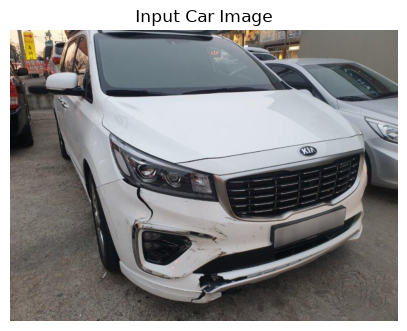

PREDICTION RESULT
-----------------------------------
Actual Class     : F_Breakage
Predicted Class  : F_Breakage
Confidence       : 99.81%

Class Probabilities:
F_Breakage     : 99.81%
F_Crushed      : 0.18%
F_Normal       : 0.01%
R_Breakage     : 0.00%
R_Crushed      : 0.00%
R_Normal       : 0.00%


In [10]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

from src.car_damage.predict import predict_image

# Select one sample image
DATASET_DIR = PROJECT_ROOT / "Dataset"

sample_image = next(
    (DATASET_DIR / "F_Breakage").glob("*")
)

# Generate prediction
result = predict_image(
    image_path=sample_image,
    model=inference_model,
    device=inference_device
)

# Display original image
image = Image.open(sample_image).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Input Car Image")
plt.show()

# Display prediction
print("PREDICTION RESULT")
print("-" * 35)

print("Actual Class     :", "F_Breakage")
print("Predicted Class  :", result["predicted_class"])
print("Confidence       :", f"{result['confidence'] * 100:.2f}%")

print("\nClass Probabilities:")

for class_name, probability in result["class_probabilities"].items():
    print(f"{class_name:15s}: {probability * 100:.2f}%")

### Testing Predictions Across All Classes

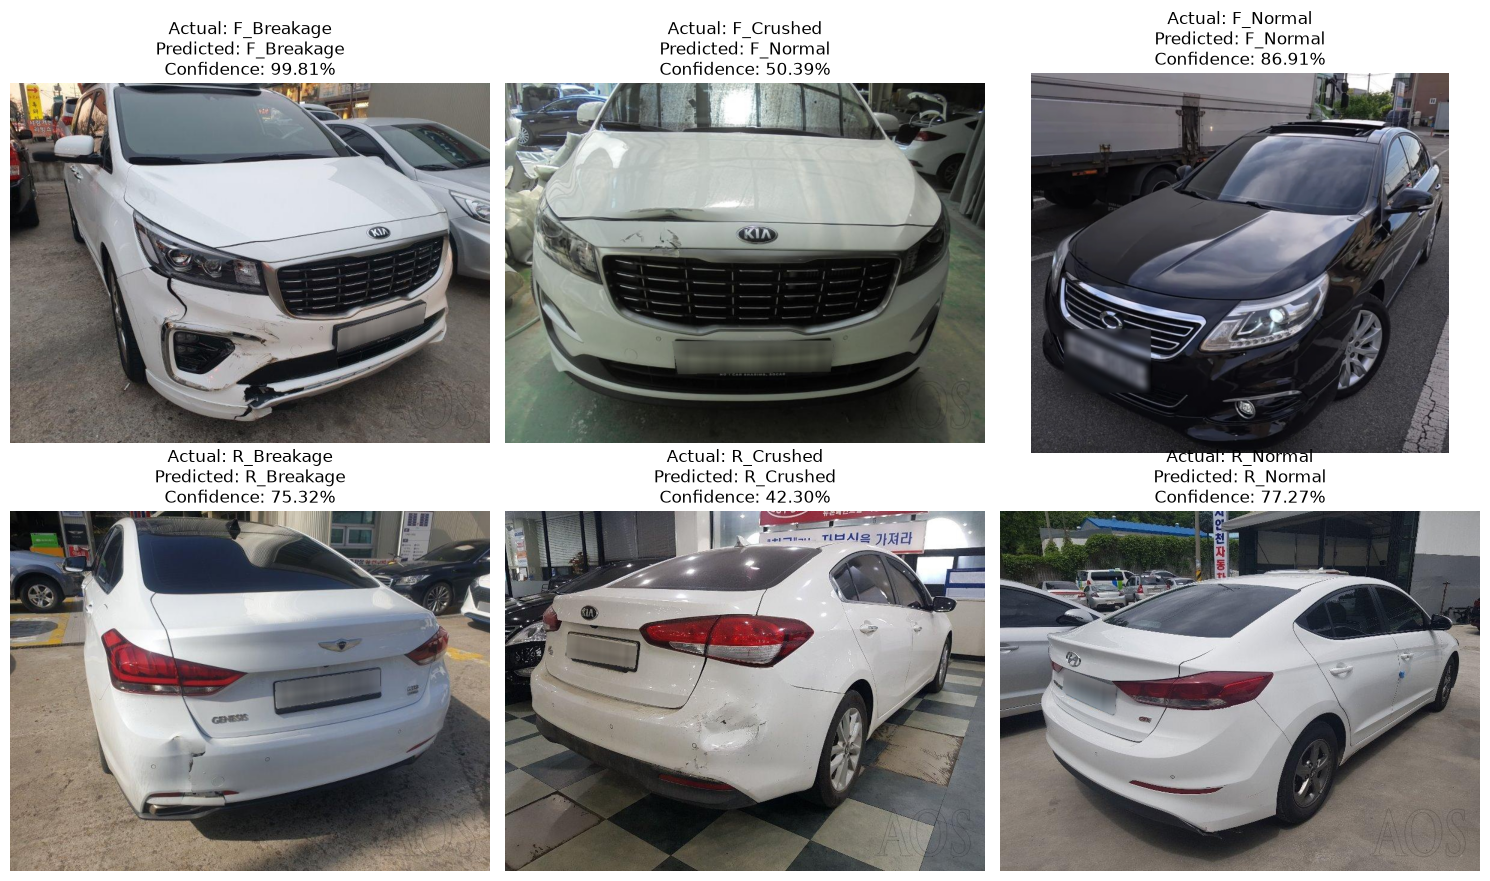

,Actual Class,Predicted Class,Confidence,Correct
0,F_Breakage,F_Breakage,0.9981,True
1,F_Crushed,F_Normal,0.5039,False
2,F_Normal,F_Normal,0.8691,True
3,R_Breakage,R_Breakage,0.7532,True
4,R_Crushed,R_Crushed,0.4230,True
5,R_Normal,R_Normal,0.7727,True


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src.car_damage.predict import predict_image

results = []

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, class_name in enumerate(class_names):

    class_folder = DATASET_DIR / class_name

    sample_image = next(
        class_folder.glob("*")
    )

    result = predict_image(
        image_path=sample_image,
        model=inference_model,
        device=inference_device
    )

    image = Image.open(sample_image).convert("RGB")

    axes[idx].imshow(image)
    axes[idx].axis("off")
    axes[idx].set_title(
        f"Actual: {class_name}\n"
        f"Predicted: {result['predicted_class']}\n"
        f"Confidence: {result['confidence']:.2%}"
    )

    results.append({
        "Actual Class": class_name,
        "Predicted Class": result["predicted_class"],
        "Confidence": result["confidence"],
        "Correct": class_name == result["predicted_class"]
    })

plt.tight_layout()
plt.show()

# Display prediction summary
prediction_df = pd.DataFrame(results)

display(prediction_df)

# Model Experiments and Observations

In this section, we experiment with different training strategies to improve our ResNet50-based car damage classification model.

Our objective is not just to maximize accuracy, but also to achieve balanced performance across all six damage categories. We use validation accuracy and macro F1-score to compare experiments and select the most suitable model.

## 1. Baseline Model – Transfer Learning with ResNet50

**Objective:** Establish a performance benchmark using a pretrained ResNet50 model.

**Observations:**
- Our baseline model achieved **73.33% accuracy** and **67.35% macro F1-score**.
- Performance varied significantly across classes, with particularly weak recognition of `R_Breakage`.
- This highlighted the need to improve the model's ability to distinguish between different rear-damage categories.

**Learning:** The pretrained model provides a useful starting point, but its classification performance needs further improvement.

## 2. Experiment 1 – AdamW Optimizer with Differential Learning Rates

**Objective:** Explore whether assigning different learning rates to the pretrained feature extractor and classification head improves learning.

**Observations:**
- We achieved **68.99% validation accuracy** and **63.99% macro F1-score**.
- The model did not outperform our baseline.
- Performance remained weak for certain rear-damage categories, particularly `R_Crushed`.

**Learning:** Differential learning rates with AdamW did not provide the expected improvement for our dataset and training configuration.

## 3. Experiment 2 – Adam Optimizer with Macro-F1-Based Checkpoint Selection

**Objective:** Improve model selection by saving the checkpoint that achieves the highest validation macro F1-score.

**Observations:**
- We achieved our best validation performance of **82.03% accuracy** and **79.62% macro F1-score**.
- The best checkpoint was selected at **epoch 4**.
- Validation performance declined in epoch 5, indicating that additional training did not improve generalization.

**Learning:** Selecting checkpoints based on validation macro F1 helped us retain the model with the best overall class-wise balance. We selected this experiment as our final model candidate.

## 4. Experiment 3 – Class-Weighted Cross-Entropy Loss

**Objective:** Address class imbalance by assigning higher loss weights to classes with fewer training samples.

**Observations:**
- We achieved **75.94% validation accuracy** and **73.97% macro F1-score**.
- The best checkpoint was selected at **epoch 2**.
- Despite using class weights, the model did not outperform Experiment 2.

**Learning:** Class weighting is a useful technique for addressing class imbalance, but it does not guarantee better overall performance. Its effectiveness depends on the dataset and model configuration.

## 5. Experiment 4 – Fine-Tuning Layer3 and Layer4

**Objective:** Explore whether unfreezing additional ResNet50 layers helps the model learn more dataset-specific visual features.

**Observations:**
- We achieved **72.17% validation accuracy** and **70.66% macro F1-score**.
- Training performance continued to improve, while validation performance fluctuated.
- The best checkpoint was selected at **epoch 3**.

**Learning:** Fine-tuning additional layers did not improve generalization in our experiments and showed signs of possible overfitting.

## 6. Experiment Comparison and Model Selection

After comparing all five approaches, we identified Experiment 2 as our best-performing model candidate.

| Experiment | Validation Accuracy | Validation Macro F1 |
|---|---:|---:|
| Baseline | 73.33%* | 67.35%* |
| Experiment 1 | 68.99% | 63.99% |
| Experiment 2 | **82.03%** | **79.62%** |
| Experiment 3 | 75.94% | 73.97% |
| Experiment 4 | 72.17% | 70.66% |

*Baseline figures are from the supplied baseline evaluation; confirm that they were calculated on the same split before treating this table as a strictly like-for-like comparison.*

**Final Decision:**

We selected Experiment 2 because it achieved the highest recorded accuracy and macro F1-score among the experiments.

We will now load its best checkpoint and evaluate it on the untouched test dataset. This final evaluation will help us estimate how well our selected model performs on previously unseen images.